In [47]:
from rdkit import Chem
import pickle
import os
import json
import joblib
import numpy as np

In [27]:
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [3]:
reactions_dir = "reactions"
reaction_id = 15
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")

Converted 27 pickle files to RDKit Mol objects.


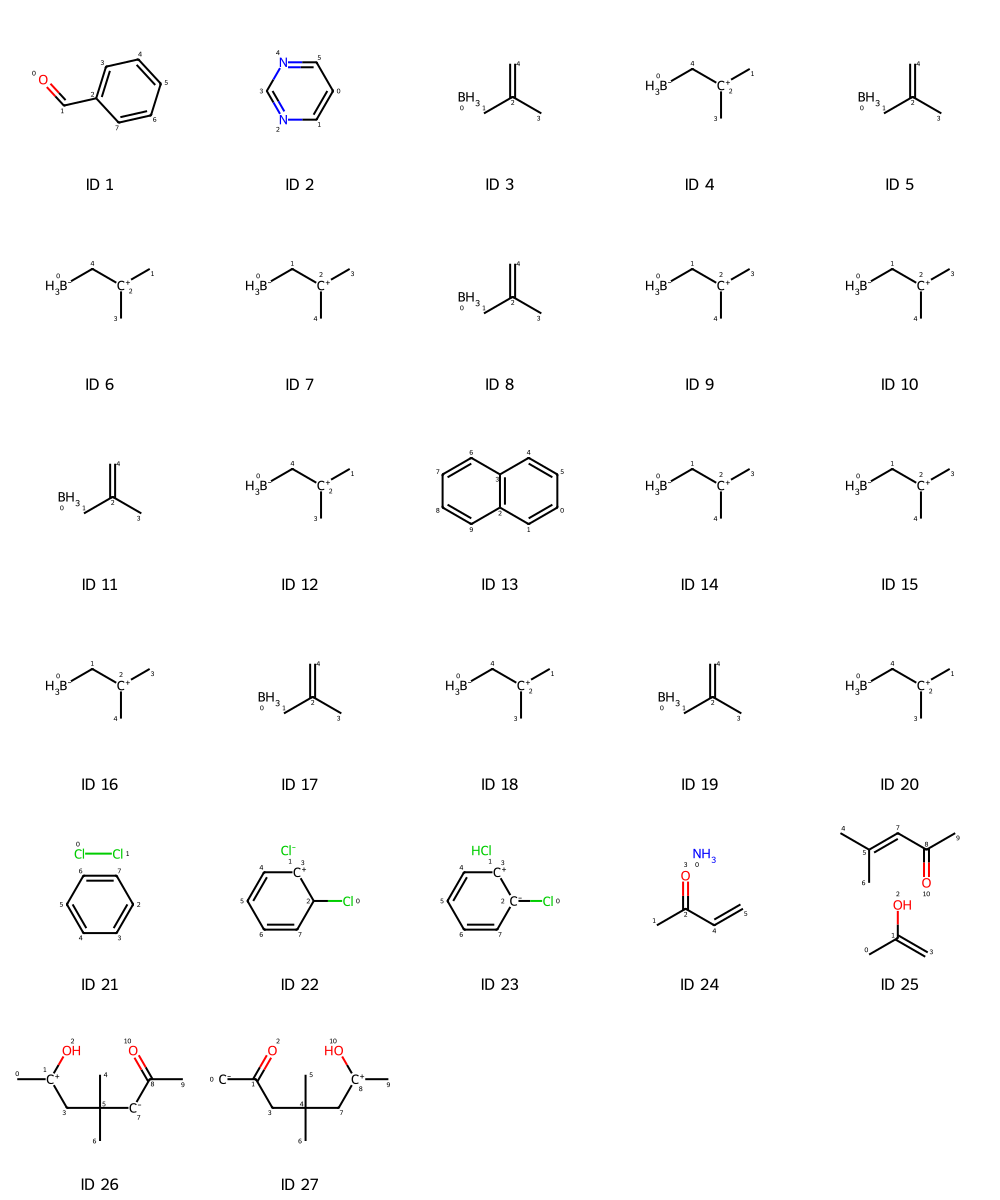

In [4]:
opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)

In [19]:
training_id = 16
training_dir = os.path.join("training", str(training_id))
t_mol_objects = []

for root, dirs, files in os.walk(training_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        if file == "sm.pkl":
                            sm = mol
                        else:
                            t_mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    
with open(os.path.join(training_dir,'data.json'), 'r') as file:
    data = json.load(file)

t_mol_objects = [sm] + t_mol_objects

print(f"Converted {len(t_mol_objects)} pickle files to RDKit Mol objects.")
print(data)

Converted 19 pickle files to RDKit Mol objects.
{'choices': {'0': {'mechanism': [6, 0, 7, None, None], 'probable': 1}, '1': {'mechanism': [7, 0, 11, None, 12], 'probable': 0}, '2': {'mechanism': [7, 0, 12, None, 11], 'probable': 0}, '3': {'mechanism': [5, 11, 6, 12, None], 'probable': 0}, '4': {'mechanism': [5, 12, 6, 11, None], 'probable': 0}, '5': {'mechanism': [1, 11, 7, 12, None], 'probable': 0}, '6': {'mechanism': [1, 12, 7, 11, None], 'probable': 0}, '7': {'mechanism': [5, 11, 8, 12, None], 'probable': 0}, '8': {'mechanism': [5, 12, 8, 11, None], 'probable': 0}, '9': {'mechanism': [5, 3, 6, 0, None], 'probable': 0}, '10': {'mechanism': [1, 3, 7, 0, None], 'probable': 0}, '11': {'mechanism': [5, 3, 8, 0, None], 'probable': 0}, '12': {'mechanism': [5, 8, 6, 0, None], 'probable': 0}, '13': {'mechanism': [1, 8, 7, 0, None], 'probable': 0}, '14': {'mechanism': [3, 3, 11, 0, 12], 'probable': 0}, '15': {'mechanism': [3, 3, 12, 0, 11], 'probable': 0}, '16': {'mechanism': [3, 8, 11, 0, 12

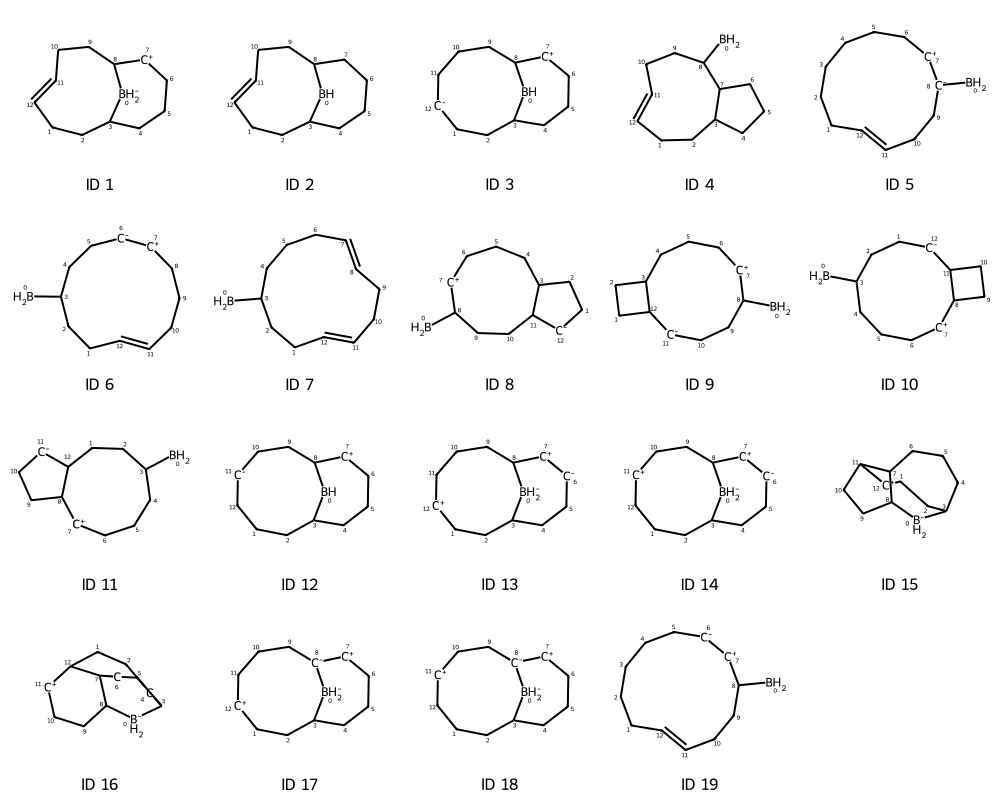

In [20]:
Chem.Draw.MolsToGridImage(t_mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(t_mol_objects))], drawOptions=opt)

In [ ]:
def make_atom_fingerprint(atom):

    # Charge bitstring
    charge_bitstring = [0] * 3
    if atom.GetFormalCharge() < 0:
        charge_bitstring[0] = 1
    elif atom.GetFormalCharge() == 0:
        charge_bitstring[1] = 1
    elif atom.GetFormalCharge() > 0:
        charge_bitstring[2] = 1

    # H bitstring
    h_number_bitstring = [0] * 4
    if atom.GetTotalNumHs() == 0:
        h_number_bitstring[0] = 1
    elif atom.GetTotalNumHs() == 1:
        h_number_bitstring[1] = 1
    elif atom.GetTotalNumHs() == 2:
        h_number_bitstring[2] = 1
    elif atom.GetTotalNumHs() > 2:
        h_number_bitstring[3] = 1

    # Hybridization bitstring
    hybridization_bitstring = [0] * 3
    if atom.GetHybridization() == Chem.rdchem.HybridizationType.SP:
        hybridization_bitstring[0] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP2:
        hybridization_bitstring[1] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP3:
        hybridization_bitstring[2] = 1

    # Element bitstring
    # [AlkMet, B, C, N, O, F, Mg, Al, Si, P, S, Cl, Br, I, Met]
    ptable = Chem.GetPeriodicTable()
    element_bitstring = [0] * 15
    dict_elements = { 5: 1,
                      6: 2,
                      7: 3,
                      8: 4,
                      9: 5,
                      12: 6,
                      13: 7,
                      14: 8,
                      15: 9,
                      16: 10,
                      17: 11,
                      35: 12,
                      53: 13}
    atm_num = atom.GetAtomicNum()
    if atm_num in dict_elements:
        element_bitstring[dict_elements[atm_num]] = 1
    elif ptable.GetNOuterElecs(atm_num) == 1:
        element_bitstring[0] = 1
    elif atm_num <= 30 and atm_num >= 20:
        element_bitstring[14] = 1

    # TODO: aromaticity bitstring

    # adjacency bitstring
    # [C+, C-, CH, C-EN, C=EN, EN, EP]
    adjecency_bitstring = [0] * 8
    for a in atom.GetNeighbors():
        if a.GetAtomicNum() == 6:
            if a.GetFormalCharge() > 0:
                adjecency_bitstring[0] = 1
            elif a.GetFormalCharge() < 0:
                adjecency_bitstring[1] = 1
            if a.GetTotalNumHs() > 0:
                adjecency_bitstring[2] = 1
            for a2 in a.GetNeighbors():
                if electronegativity_dict[a2.GetAtomicNum()] > 2.55:
                    for b in a.GetBonds():
                        if b.GetOtherAtom(a).GetIdx() == a2.GetIdx():
                            if b.GetBondTypeAsDouble() == 1:
                                adjecency_bitstring[3] = 1
                            elif b.GetBondTypeAsDouble() >= 2:
                                adjecency_bitstring[4] = 1
        elif electronegativity_dict[a.GetAtomicNum()] > 2.55:
            adjecency_bitstring[5] = 1
        elif electronegativity_dict[a.GetAtomicNum()] < 2.05:
            adjecency_bitstring[6] = 1
 
    

    total_bit_string = charge_bitstring + h_number_bitstring + hybridization_bitstring + element_bitstring + adjecency_bitstring
    return total_bit_string

   
def make_bond_fingerprint(bond):
    # bond type bitstring
    # [single, double, triple, aromatic]
    bond_type_bitstring = [0] * 4
    if not bond:
        return bond_type_bitstring
    if bond.GetBondTypeAsDouble() == 1:
        bond_type_bitstring[0] = 1
    elif bond.GetBondTypeAsDouble() == 2:
        bond_type_bitstring[1] = 1
    elif bond.GetBondTypeAsDouble() == 3:
        bond_type_bitstring[2] = 1
    elif bond.GetBondTypeAsDouble() == 4:
        bond_type_bitstring[3] = 1
    return bond_type_bitstring


def new_bond_fingerprint(mol, a1_idx, a2_idx):
    a1 = mol.GetAtomWithIdx(a1_idx)
    a2 = mol.GetAtomWithIdx(a2_idx)
    # ring size bitstring
    # [3, 4, 5, 6, 7+]
    ring_size_bitstring = [0] * 5
    fragments = Chem.GetMolFrags(mol)
    for f in fragments:
        if a1.GetIdx() in f and a2.GetIdx() in f:
            len_path = len(Chem.GetShortestPath(mol, a1.GetIdx(), a2.GetIdx()))
            if len_path == 3:
                ring_size_bitstring[0] = 1
            elif len_path == 4:
                ring_size_bitstring[1] = 1
            elif len_path == 5:
                ring_size_bitstring[2] = 1
            elif len_path == 6:
                ring_size_bitstring[3] = 1
            elif len_path >= 7:
                ring_size_bitstring[4] = 1
    return ring_size_bitstring


In [42]:
# Data analysis

arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
}


training_dir = "training"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []

for subdir in subdirs:
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    for id, info in choices.items():
        #print(arrow_types[info['mechanism'][0]])
        if info['mechanism'][0] < 4 or True:
            a1 = make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][1]))
            a2 = make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][2]))
            if info['mechanism'][3]:
                b1 = make_bond_fingerprint(sm.GetBondBetweenAtoms(info['mechanism'][1], info['mechanism'][3]))
            else:
                b1 = [0] *4
            if info['mechanism'][4]:
                b2 = make_bond_fingerprint(sm.GetBondBetweenAtoms(info['mechanism'][2], info['mechanism'][4]))
            else:
                b2 = [0] *4
            r = new_bond_fingerprint(sm, info['mechanism'][1], info['mechanism'][2])
            sum_finger_print = [info['mechanism'][0]] + a1 + a2 + b1 + b2 + r
            bitvectors.append(sum_finger_print)
            outcomes.append(info['probable'])



In [67]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score

In [82]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
joblib.dump(clf, 'model.pkl')

Accuracy: 0.9322916666666666
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.99      0.96       173
           1       0.80      0.42      0.55        19

    accuracy                           0.93       192
   macro avg       0.87      0.70      0.76       192
weighted avg       0.93      0.93      0.92       192



['model.pkl']

In [69]:
m = Chem.MolFromSmiles('CCO')
Chem.GetShortestPath(m, 0, 1)
print(bool(m.GetBondBetweenAtoms(0,2)))

False


In [70]:
print(np.sum(np.array(outcomes)))

103


In [71]:
len(outcomes)

765

In [72]:
1 - 103/765

0.865359477124183

In [73]:
from xgboost import XGBClassifier

In [86]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 11, eval_metric='logloss')
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
joblib.dump(clf, 'xg_model.pkl')

              precision    recall  f1-score   support

           0       0.97      0.93      0.95       164
           1       0.66      0.82      0.73        28

    accuracy                           0.91       192
   macro avg       0.81      0.87      0.84       192
weighted avg       0.92      0.91      0.92       192



['xg_model.pkl']

In [84]:
precisions =[]
recalls = []
pos_weight = 15
iter = 10
for i in range(pos_weight):
    precision = 0
    recall = 0
    for k in range(iter):
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)
        clf = XGBClassifier(scale_pos_weight = i+1, eval_metric='logloss')
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        #print(classification_report(y_test, y_pred))
        recall += recall_score(y_test, y_pred)/iter
        precision += precision_score(y_test, y_pred)/iter
    precisions.append(precision)
    recalls.append(recall)


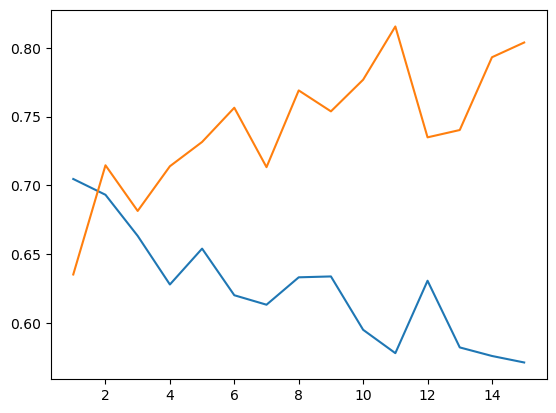

In [85]:
from matplotlib import pyplot as plt
plt.plot(range(1, pos_weight+1), precisions, label='Precision')
plt.plot(range(1, pos_weight+1), recalls, label='Recall')
plt.show()